

Cada personaje es un nodo y hay una arista entre dos personajes si uno se menciona a menos de 15 palabras del otro; el peso de la arista es el número de veces que eso pasa en la novela. La novela es Cien años de soledad. 

In [1]:
import os
import re
import math
import json
import html
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
from IPython.display import HTML, display

## I. Construcción de la red

### Texto

En esta edición cada uno de los 20 capítulos es un archivo del epub (`0001.xhtml` a `0020.xhtml`). Quito el prólogo, los ensayos y el glosario de la edición conmemorativa.

In [ ]:
archivo = "cien_años_de_soledad.epub"
if not os.path.exists(archivo):
    from google.colab import files  
    archivo = next(iter(files.upload()))

capitulos = []
with zipfile.ZipFile(archivo) as z:
    for k in range(1, 21):
        xhtml = z.read(f"OEBPS/Text/{k:04d}.xhtml").decode("utf-8")
        cuerpo = xhtml.split("<body", 1)[1]
        capitulos.append(html.unescape(re.sub(r"<[^>]+>", " ", cuerpo)))

patron = r"\b[\wÁÉÍÓÚÜÑáéíóúüñ]+\b"
palabras_por_capitulo = [len(re.findall(patron, c)) for c in capitulos]
print("palabras por capítulo:", palabras_por_capitulo)
print("total:", sum(palabras_por_capitulo))

palabras por capítulo: [5878, 6118, 7531, 6853, 7789, 5892, 6674, 6367, 6483, 7050, 6700, 6972, 7878, 8060, 7184, 6413, 7447, 7187, 7307, 6237]
total: 138020


### Personajes


- "José Arcadio" 
- "Aureliano" 
- "Remedios" 

Los cortes se eligieron contando en qué capítulos aparece cada form, no apdos. 

In [ ]:
todos = (1, 20)
alias = [

    ("José Arcadio Buendía", "José Arcadio Buendía", todos),
    ("Úrsula Iguarán", "Úrsula", todos),
    ("Úrsula", "Úrsula", todos),
    ("José Arcadio", "José Arcadio", (1, 10)),
    ("José Arcadio", "José Arcadio (seminarista)", (11, 20)),
    ("Aureliano Buendía", "Coronel Aureliano Buendía", todos),
    ("Aureliano", "Coronel Aureliano Buendía", (1, 14)),
    ("Aureliano", "Aureliano Babilonia", (15, 20)),
    ("Aureliano Babilonia", "Aureliano Babilonia", todos),
    ("Amaranta", "Amaranta", todos),
    ("Rebeca", "Rebeca", todos),
    ("Pilar Ternera", "Pilar Ternera", todos),
    ("Pilar", "Pilar Ternera", todos),
    ("Melquíades", "Melquíades", todos),
    ("Arcadio", "Arcadio", todos),
    ("Remedios Moscote", "Remedios Moscote", todos),
    ("Remedios", "Remedios Moscote", (1, 7)),
    ("Remedios la bella", "Remedios, la bella", todos),
    ("Remedios", "Remedios, la bella", (8, 20)),
    ("Apolinar Moscote", "Apolinar Moscote", todos),
    ("don Apolinar", "Apolinar Moscote", todos),
    ("Amparo Moscote", "Amparo Moscote", todos),
    ("Pietro Crespi", "Pietro Crespi", todos),
    ("Crespi", "Pietro Crespi", todos),
    ("Santa Sofía de la Piedad", "Santa Sofía de la Piedad", todos),
    ("Santa Sofía", "Santa Sofía de la Piedad", todos),
    ("Aureliano José", "Aureliano José", todos),
    ("Gerineldo Márquez", "Gerineldo Márquez", todos),
    ("Gerineldo", "Gerineldo Márquez", todos),
    ("José Raquel Moncada", "José Raquel Moncada", todos),
    ("Moncada", "José Raquel Moncada", todos),
    ("Prudencio Aguilar", "Prudencio Aguilar", todos),
    ("Visitación", "Visitación", todos),
    ("Cataure", "Cataure", todos),
    ("Catarino", "Catarino", todos),
    ("Nicanor", "Padre Nicanor", todos),
    ("Aureliano Segundo", "Aureliano Segundo", todos),
    ("José Arcadio Segundo", "José Arcadio Segundo", todos),
    ("Fernanda", "Fernanda del Carpio", todos),
    ("Petra Cotes", "Petra Cotes", todos),
    ("Meme", "Meme", todos),
    ("Renata Remedios", "Meme", todos),
    ("Amaranta Úrsula", "Amaranta Úrsula", todos),
    ("Mauricio Babilonia", "Mauricio Babilonia", todos),
    ("Aureliano Triste", "Aureliano Triste", todos),
    ("Aureliano Amador", "Aureliano Amador", todos),
    ("Brown", "Mr. Brown", todos),
    ("Patricia Brown", "Patricia Brown", todos),
    ("Herbert", "Mr. Herbert", todos),
    ("Gastón", "Gastón", todos),
    ("Nigromanta", "Nigromanta", todos),
    ("Gabriel", "Gabriel", todos),
    ("Alfonso", "Alfonso", todos),
    ("Germán", "Germán", todos),
    ("Álvaro", "Álvaro", todos),
    ("Antonio Isabel", "Padre Antonio Isabel", todos),
    ("Magnífico Visbal", "Magnífico Visbal", todos),
    ("Roque Carnicero", "Roque Carnicero", todos),
    ("Camila Sagastume", "Camila Sagastume", todos),
    ("Elefanta", "Camila Sagastume", todos),
    ("Francisco el Hombre", "Francisco el Hombre", todos),
    ("Carmelita Montiel", "Carmelita Montiel", todos),
]
personajes = list(dict.fromkeys(p for _, p, _ in alias))
print(len(personajes), "personajes,", len(alias), "formas de nombrarlos")

49 personajes, 62 formas de nombrarlos


### Matriz de adyacencias

 radio = 15.

In [ ]:
radio = 15

def normalizar(s):
    return s.casefold()

def tokenizar(s):
    return [normalizar(p) for p in re.findall(patron, s)]

tokens, capitulo_de = [], []
for k, c in enumerate(capitulos, start=1):
    t = tokenizar(c)
    tokens += t
    capitulo_de += [k] * len(t)

por_inicio = {}
for nombre, personaje, (c1, c2) in sorted(alias, key=lambda a: -len(tokenizar(a[0]))):
    t = tokenizar(nombre)
    por_inicio.setdefault(t[0], []).append((t, personaje, c1, c2))

ocurrencias = [] 
i = 0
while i < len(tokens):
    for t, personaje, c1, c2 in por_inicio.get(tokens[i], []):
        if tokens[i:i + len(t)] == t and c1 <= capitulo_de[i] <= c2:
            ocurrencias.append((i, i + len(t) - 1, personaje))
            i += len(t) - 1
            break
    i += 1

print("apariciones encontradas:", len(ocurrencias))

apariciones encontradas: 3347


In [5]:
indice = {p: k for k, p in enumerate(personajes)}
apariciones = {p: 0 for p in personajes}
for _, _, p in ocurrencias:
    apariciones[p] += 1

n = len(personajes)
matriz = np.zeros((n, n), dtype=int)

for i in range(len(ocurrencias)):
    inicio_a, fin_a, personaje_a = ocurrencias[i]
    for j in range(i + 1, len(ocurrencias)):
        inicio_b, fin_b, personaje_b = ocurrencias[j]
        distancia = max(0, inicio_b - fin_a - 1)
        if distancia > radio:
            break
        if personaje_a != personaje_b:
            matriz[indice[personaje_a], indice[personaje_b]] += 1
            matriz[indice[personaje_b], indice[personaje_a]] += 1

conteo_apariciones = pd.Series(apariciones, name="Apariciones").sort_values(ascending=False)
matriz_interacciones = pd.DataFrame(matriz, index=personajes, columns=personajes)

display(conteo_apariciones.head(20).to_frame().T)
principales = conteo_apariciones.index[:12]
matriz_interacciones.loc[principales, principales]

,Úrsula,Coronel Aureliano Buendía,Amaranta,Fernanda del Carpio,Aureliano Segundo,José Arcadio Buendía,Aureliano Babilonia,Rebeca,Meme,Melquíades,Arcadio,Amaranta Úrsula,José Arcadio Segundo,José Arcadio,Gerineldo Márquez,Pietro Crespi,"Remedios, la bella",Petra Cotes,Pilar Ternera,Santa Sofía de la Piedad
Apariciones,427,366,222,216,206,174,158,127,109,102,91,86,84,77,76,72,71,70,61,58


,Úrsula,Coronel Aureliano Buendía,Amaranta,Fernanda del Carpio,Aureliano Segundo,José Arcadio Buendía,Aureliano Babilonia,Rebeca,Meme,Melquíades,Arcadio,Amaranta Úrsula
Úrsula,0,39,43,21,19,21,4,18,8,7,12,7
Coronel Aureliano Buendía,39,0,13,3,13,13,5,14,2,5,10,0
Amaranta,43,13,0,11,2,5,0,32,10,2,10,1
Fernanda del Carpio,21,3,11,0,23,3,9,0,27,1,0,11
Aureliano Segundo,19,13,2,23,0,0,3,0,18,3,0,2
José Arcadio Buendía,21,13,5,3,0,0,0,5,0,12,2,0
Aureliano Babilonia,4,5,0,9,3,0,0,0,0,11,2,25
Rebeca,18,14,32,0,0,5,0,0,0,3,7,0
Meme,8,2,10,27,18,0,0,0,0,0,1,2
Melquíades,7,5,2,1,3,12,11,3,0,0,3,1


Se quitan los personajes con menos de 3 apariciones y los que no quedan conectados con nadie. Red no dirigida y pesada.

In [6]:
G = nx.from_pandas_adjacency(matriz_interacciones)
G.remove_nodes_from([p for p in personajes if apariciones[p] < 3])
G.remove_nodes_from(list(nx.isolates(G)))
nx.set_node_attributes(G, {p: int(apariciones[p]) for p in G}, "apariciones")
print("nodos:", G.number_of_nodes(), "  aristas:", G.number_of_edges())

nodos: 49   aristas: 268


## II. Dibujo de la red

Se usa cytoscape.js, 

In [ ]:
comunidades = nx.community.louvain_communities(G, weight="weight", seed=1)
comunidades = sorted(comunidades, key=lambda c: np.median([capitulo_de[i] for i, _, p in ocurrencias if p in c]))
comunidad = {p: k for k, c in enumerate(comunidades) for p in c}
nx.set_node_attributes(G, comunidad, "comunidad")

colores = ["#4e79a7", "#e15759", "#59a14f", "#f28e2b", "#b07aa1", "#76b7b2"]
peso_max = max(d["weight"] for _, _, d in G.edges(data=True))

elementos = [{"data": {"id": p, "apariciones": int(apariciones[p]),
                       "color": colores[comunidad[p] % len(colores)]}} for p in G]
elementos += [{"data": {"source": a, "target": b, "peso": int(d["weight"])}}
              for a, b, d in G.edges(data=True)]

plantilla = """
<div id="red-cy" style="width: 100%; height: 680px; border: 1px solid #ddd; background: white;"></div>
<script>
(function () {
  var elementos = __ELEMENTOS__;
  function dibujar(cytoscape) {
    var cy = cytoscape({
      container: document.getElementById("red-cy"),
      elements: elementos,
      style: [
        {selector: "node", style: {
          "label": "data(id)", "background-color": "data(color)",
          "width": "mapData(apariciones, 3, __APMAX__, 10, 48)",
          "height": "mapData(apariciones, 3, __APMAX__, 10, 48)",
          "font-size": 10, "color": "#222", "text-valign": "top",
          "text-outline-color": "#fff", "text-outline-width": 2}},
        {selector: "edge", style: {
          "width": "mapData(peso, 1, __PESOMAX__, 0.5, 9)",
          "opacity": "mapData(peso, 1, __PESOMAX__, 0.15, 0.8)",
          "line-color": "#888", "curve-style": "haystack"}},
        {selector: ".tenue", style: {"opacity": 0.06}}
      ],
      layout: {name: "cose", animate: false, randomize: false, nodeRepulsion: 60000,
               idealEdgeLength: 130, edgeElasticity: 60, gravity: 0.4, numIter: 2500,
               nodeOverlap: 20}
    });
    cy.on("tap", "node", function (e) {
      var vecinos = e.target.closedNeighborhood();
      cy.elements().addClass("tenue");
      vecinos.removeClass("tenue");
    });
    cy.on("tap", function (e) { if (e.target === cy) cy.elements().removeClass("tenue"); });
  }
  var url = "https://cdnjs.cloudflare.com/ajax/libs/cytoscape/3.30.2/cytoscape.min.js";
  if (typeof window.require === "function" && window.define && window.define.amd) {
    window.require([url], dibujar);   // la página de Quarto trae require.js
  } else if (window.cytoscape) {
    dibujar(window.cytoscape);
  } else {
    var s = document.createElement("script");
    s.src = url;
    s.onload = function () { dibujar(window.cytoscape); };
    document.head.appendChild(s);
  }
})();
</script>
"""

pos = nx.spring_layout(G, weight="weight", k=0.4, iterations=200, seed=3)
for e in elementos[:G.number_of_nodes()]:
    x, y = pos[e["data"]["id"]]
    e["position"] = {"x": float(600 * x), "y": float(600 * y)}

html_red = (plantilla.replace("__ELEMENTOS__", json.dumps(elementos, ensure_ascii=False))
                     .replace("__APMAX__", str(max(apariciones.values())))
                     .replace("__PESOMAX__", str(peso_max)))
display(HTML(html_red))

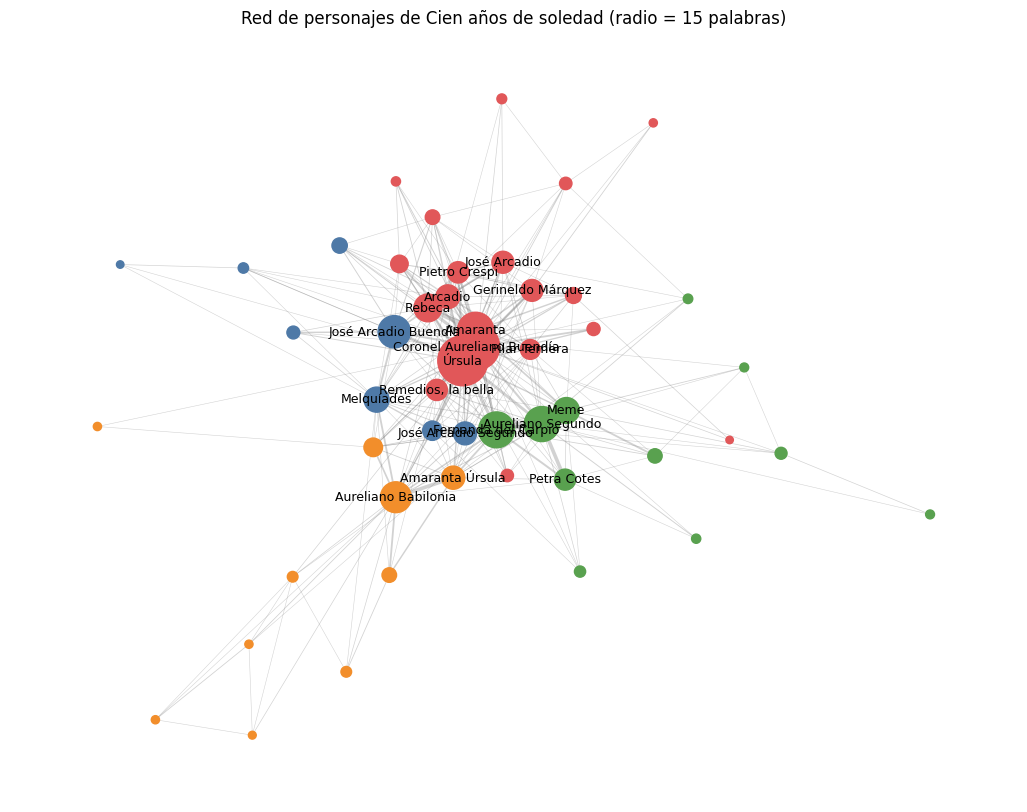

In [ ]:
nx.write_graphml(G, "red_cien_anos.graphml")

# misma red en una figura fija
plt.figure(figsize=(13, 10))
nx.draw_networkx_edges(G, pos, width=[0.3 + 4 * d["weight"] / peso_max for _, _, d in G.edges(data=True)],
                       alpha=0.35, edge_color="gray")
nx.draw_networkx_nodes(G, pos, node_size=[20 + 3 * apariciones[p] for p in G],
                       node_color=[colores[comunidad[p]] for p in G])
nx.draw_networkx_labels(G, pos, {p: p for p in G if apariciones[p] >= 60}, font_size=9)
plt.title("Red de personajes de Cien años de soledad (radio = 15 palabras)")
plt.axis("off")
plt.show()

## III. Análisis

### Tamaño, densidad y componentes

In [ ]:
n, m = G.number_of_nodes(), G.number_of_edges()
grados = dict(G.degree())
fuerza = dict(G.degree(weight="weight"))
print("n =", n, "  m =", m)
print("densidad 2m/(n(n-1)) =", round(2*m / (n*(n - 1)), 3))
print("grado promedio =", round(2*m / n, 2))
print("componentes conexas:", nx.number_connected_components(G))

L_lap = nx.laplacian_matrix(G).toarray()  
valores = np.sort(np.linalg.eigvalsh(L_lap))
print("autovalores cero del laplaciano:", int(np.sum(np.abs(valores) < 1e-9)))
print("valor de Fiedler:", round(valores[1], 3))

n = 49   m = 268
densidad 2m/(n(n-1)) = 0.228
grado promedio = 10.94
componentes conexas: 1
autovalores cero del laplaciano: 1
valor de Fiedler: 1.988


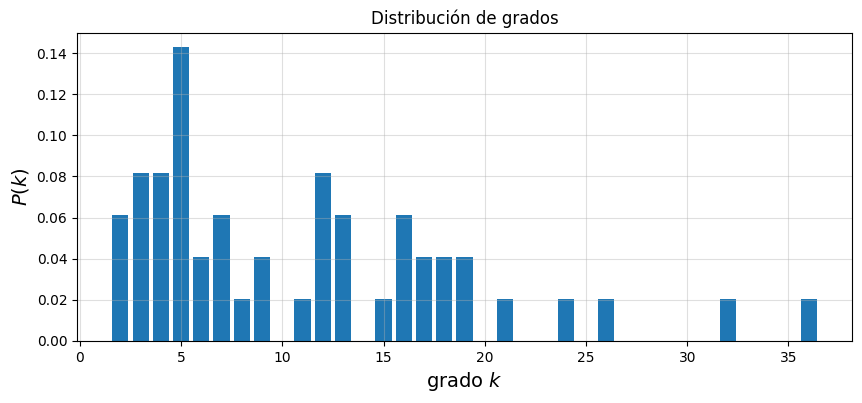

los de mayor grado: [('Coronel Aureliano Buendía', 36), ('Úrsula', 32), ('Amaranta', 26), ('Aureliano Segundo', 24), ('Melquíades', 21), ('Aureliano Babilonia', 19)]
mediana del grado: 9.0
fracción con grado <= 7: 0.47   en una Poisson con la misma media: 0.15


In [10]:
k, cuantos = np.unique(list(grados.values()), return_counts=True)
plt.figure(figsize=(10, 4))
plt.bar(k, cuantos / n, color="tab:blue")
plt.xlabel("grado $k$", fontsize=14)
plt.ylabel("$P(k)$", fontsize=14)
plt.title("Distribución de grados")
plt.grid(alpha=0.4)
plt.show()

print("los de mayor grado:", sorted(grados.items(), key=lambda x: -x[1])[:6])
print("mediana del grado:", np.median(list(grados.values())))
lam = 2*m / n
print("fracción con grado <= 7:", round(np.mean(np.array(list(grados.values())) <= 7), 2),
      "  en una Poisson con la misma media:", round(sum(np.exp(-lam) * lam**j / math.factorial(j) for j in range(8)), 2))

Lad red es conexa (un solo autovalor cero del laplaciano), y el valor de Fiedler, 1.99, llo que indica que no hay un corte fácil que la parta en dos.

### Distancias y mundo pequeño

Distancias y las centralidades se calculan sobre la red sin pesos Conf., de la comparación: 200 redes de Erdős-Rényi $G(n, m)$ con los mismos $n$ y $m$.

In [11]:
L = nx.average_shortest_path_length(G)
C = nx.average_clustering(G)
T = nx.transitivity(G)
print("L promedio =", round(L, 3), "  diámetro =", nx.diameter(G), "  radio =", nx.radius(G))
print("centro:", nx.center(G))
print("periferia:", len(nx.periphery(G)), "de", n, "nodos")

aleatorias = []
for semilla in range(200):
    A = nx.gnm_random_graph(n, m, seed=semilla)
    if nx.is_connected(A):
        aleatorias.append((nx.average_shortest_path_length(A), nx.average_clustering(A), nx.transitivity(A)))
aleatorias = np.array(aleatorias)

pd.DataFrame({"red de la novela": [L, C, T],
              "Erdős-Rényi (promedio)": aleatorias.mean(axis=0),
              "Erdős-Rényi (desv. est.)": aleatorias.std(axis=0)},
             index=["L", "C promedio", "transitividad"]).round(3)

L promedio = 1.924   diámetro = 3   radio = 2
centro: ['Úrsula', 'José Arcadio (seminarista)', 'Coronel Aureliano Buendía', 'Aureliano Babilonia', 'Pilar Ternera', 'Melquíades', 'Remedios, la bella', 'Santa Sofía de la Piedad', 'Aureliano Segundo', 'José Arcadio Segundo', 'Fernanda del Carpio', 'Petra Cotes']
periferia: 37 de 49 nodos


,red de la novela,Erdős-Rényi (promedio),Erdős-Rényi (desv. est.)
L,1.924,1.834,0.009
C promedio,0.706,0.228,0.014
transitividad,0.493,0.226,0.012


La distancia promedio es 1.92 y el diámetro 3, por lo qye que de cualquier personaje a cualquier otro se llega en a lo más tres pasos. 


### Centralidad

In [12]:
tabla = pd.DataFrame({
    "grado": grados,
    "fuerza": fuerza,
    "c. grado": nx.degree_centrality(G),
    "intermediación": nx.betweenness_centrality(G),
    "cercanía": nx.closeness_centrality(G),
    "acumulación": nx.clustering(G),
    "comunidad": comunidad,
})
tabla.sort_values("intermediación", ascending=False).head(15).round(3)

,grado,fuerza,c. grado,intermediación,cercanía,acumulación,comunidad
Coronel Aureliano Buendía,36,220,0.750,0.242,0.800,0.279,1
Úrsula,32,306,0.667,0.128,0.750,0.359,1
Aureliano Babilonia,19,100,0.396,0.105,0.623,0.421,3
Aureliano Segundo,24,151,0.500,0.096,0.667,0.388,2
Melquíades,21,70,0.438,0.059,0.640,0.457,0
Fernanda del Carpio,19,141,0.396,0.046,0.623,0.491,2
Amaranta,26,190,0.542,0.045,0.667,0.452,1
Meme,17,95,0.354,0.025,0.585,0.471,2
Arcadio,18,72,0.375,0.023,0.608,0.542,1
José Arcadio Buendía,16,89,0.333,0.020,0.578,0.533,0


Úrsula lidera en fuerza (306 frente a 220 del coronel), pero el coronelen intermediación (0.242 contra 0.128), en cercanía (0.80) y en número de vecinos (36). Esto se explica en parte por las guerras: Gerineldo Márquez (16), Moncada (11) y Aureliano Triste (5) tienen con él su arista más fuerte. Melquíades queda quinto en intermediación con apenas 102 apariciones, gracias a sus aristas con José Arcadio Buendía (12) y Aureliano Babilonia (11); arece al inicio, casi desaparece a mitad de la novela y regresa en los últimos capítulos.

### Comunidades

In [ ]:
print("modularidad:", round(nx.community.modularity(G, comunidades, weight="weight"), 3))
for k, c in enumerate(comunidades):
    print(f"comunidad {k} ({len(c)}):", ", ".join(sorted(c, key=lambda p: -apariciones[p])))

from collections import Counter
tamanos = Counter(tuple(sorted(len(c) for c in nx.community.louvain_communities(G, weight="weight", seed=s)))
                  for s in range(50))
print("tamaños de las comunidades en 50 semillas:", tamanos.most_common())

for p in ["Coronel Aureliano Buendía", "Úrsula", "Melquíades", "Pilar Ternera"]:
    print(p, "tiene vecinos en las comunidades", dict(sorted(Counter(comunidad[q] for q in G[p]).items())))

modularidad: 0.283
comunidad 0 (8): José Arcadio Buendía, Melquíades, José Arcadio Segundo, Santa Sofía de la Piedad, Apolinar Moscote, Prudencio Aguilar, Visitación, Cataure
comunidad 1 (20): Úrsula, Coronel Aureliano Buendía, Amaranta, Rebeca, Arcadio, José Arcadio, Gerineldo Márquez, Pietro Crespi, Remedios, la bella, Pilar Ternera, Remedios Moscote, Aureliano José, Padre Nicanor, José Raquel Moncada, Aureliano Triste, Catarino, Roque Carnicero, Amparo Moscote, Magnífico Visbal, Carmelita Montiel
comunidad 2 (11): Fernanda del Carpio, Aureliano Segundo, Meme, Petra Cotes, Mauricio Babilonia, Mr. Brown, Padre Antonio Isabel, Francisco el Hombre, Camila Sagastume, Mr. Herbert, Patricia Brown
comunidad 3 (10): Aureliano Babilonia, Amaranta Úrsula, José Arcadio (seminarista), Gastón, Nigromanta, Gabriel, Germán, Aureliano Amador, Alfonso, Álvaro
tamaños de las comunidades en 50 semillas: [((8, 10, 11, 20), 26), ((6, 10, 13, 20), 21), ((11, 13, 25), 2), ((7, 10, 11, 21), 1)]
Coronel Aure

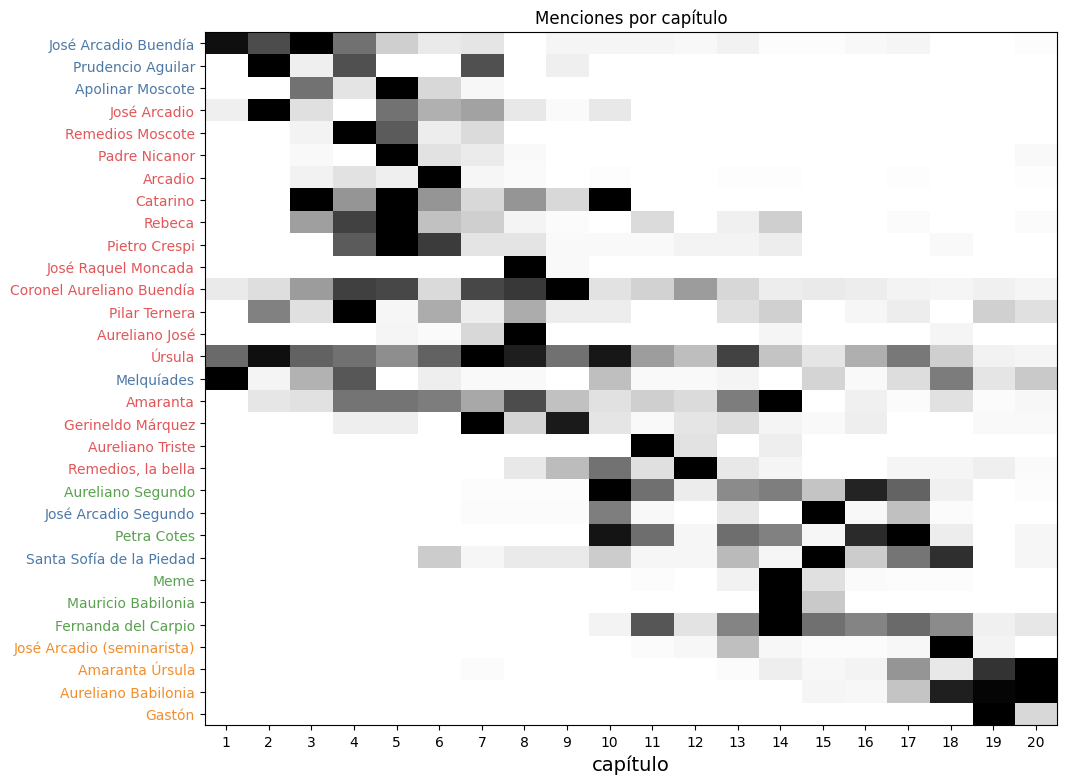

In [14]:
por_capitulo = pd.DataFrame(0, index=personajes, columns=range(1, 21))
for inicio, _, p in ocurrencias:
    por_capitulo.loc[p, capitulo_de[inicio]] += 1

filas = [p for p in G if apariciones[p] >= 20]
capitulo_medio = {p: (por_capitulo.loc[p] * por_capitulo.columns).sum() / apariciones[p] for p in filas}
filas.sort(key=capitulo_medio.get)
normalizada = por_capitulo.loc[filas].div(por_capitulo.loc[filas].max(axis=1), axis=0)

fig, ax = plt.subplots(figsize=(11, 9))
ax.imshow(normalizada, cmap="Greys", aspect="auto")
ax.set_xticks(range(20), range(1, 21))
ax.set_yticks(range(len(filas)), filas)
for etiqueta, p in zip(ax.get_yticklabels(), filas):
    etiqueta.set_color(colores[comunidad[p]])
ax.set_xlabel("capítulo", fontsize=14)
ax.set_title("Menciones por capítulo")
plt.show()

Louvain da cuatro comunidades (modularidad 0.28), numeradas por capítulo mediano: La 0 tienee a José Arcadio Buendía, Melquíades, Prudencio Aguilar, Apolinar Moscote, Visitación, Cataure, José Arcadio Segundo y Santa Sofía de la Piedad; estos dos últimos pasan a la comunidad 2 en 21 de 50 semillas. La 1 es la mayor, con 20 miembros: Úrsula, el coronel, Amaranta, Rebeca, Arcadio, José Arcadio, Pietro Crespi, Remedios Moscote, Pilar Ternera, Gerineldo Márquez, Moncada y otros. La 2 aAureliano Segundo, Fernanda, Meme, Petra Cotes, Mauricio Babilonia, Mr. Brown, Mr. Herbert y el padre Antonio Isabel. La 3 incluye a Aureliano Babilonia, Amaranta Úrsula, el seminarista, Gastón, Nigromanta, Gabriel, Álvadro, Germán y Alfonso (Úrsula, Pilar Ternera, Melquíades y el coronel tienen vecinos en las cuatro comunidades). El coronel tiene 18 de sus 36 vecinos fuera de la suya, y Melquíades 15 de 21.

### Robustez

 Se quitan nodos uno por uno, en orden de grado (ataque) o al azar (promedio de 200 órdenes) 

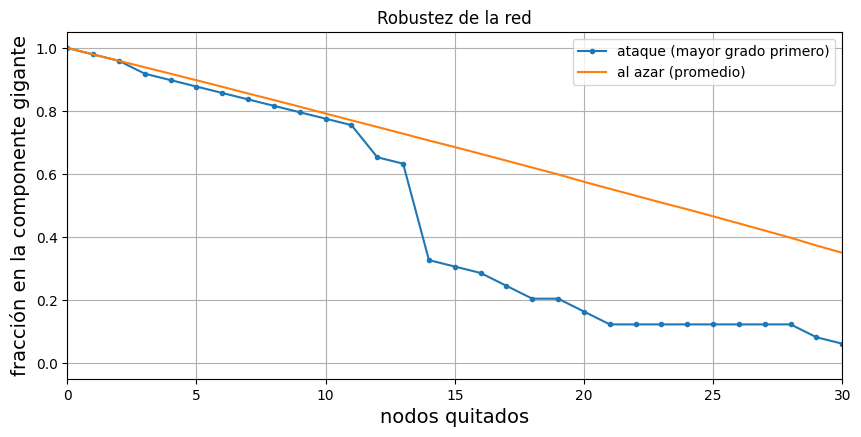

con ataque la gigante baja de la mitad al quitar 14 nodos: Coronel Aureliano Buendía, Úrsula, Amaranta, Aureliano Segundo, Melquíades, Aureliano Babilonia, Fernanda del Carpio, Rebeca, Arcadio, Pilar Ternera, Meme, José Arcadio Buendía, Remedios, la bella, Amaranta Úrsula
la gigante queda con 16 de los 35 nodos que quedan
al azar, con 14 nodos quitados la gigante conserva en promedio 34.6 nodos


In [15]:
def gigante(H):
    return max((len(c) for c in nx.connected_components(H)), default=0)

def curva(orden):
    H = G.copy()
    tamanos = [gigante(H)]
    for p in orden:
        H.remove_node(p)
        tamanos.append(gigante(H))
    return np.array(tamanos)

ataque = curva(sorted(G, key=lambda p: -grados[p]))
rng = np.random.default_rng(0)
azar = np.mean([curva(rng.permutation(list(G))) for _ in range(200)], axis=0)

quitados = np.arange(n + 1)
plt.figure(figsize=(10, 4.5))
plt.plot(quitados, ataque / n, "o-", markersize=3, label="ataque (mayor grado primero)")
plt.plot(quitados, azar / n, label="al azar (promedio)")
plt.xlabel("nodos quitados", fontsize=14)
plt.ylabel("fracción en la componente gigante", fontsize=14)
plt.title("Robustez de la red")
plt.xlim(0, 30)
plt.legend()
plt.grid()
plt.show()

orden_ataque = sorted(G, key=lambda p: -grados[p])
k = int(np.argmax(ataque < n / 2))
print("con ataque la gigante baja de la mitad al quitar", k, "nodos:", ", ".join(orden_ataque[:k]))
print("la gigante queda con", ataque[k], "de los", n - k, "nodos que quedan")
print("al azar, con", k, "nodos quitados la gigante conserva en promedio", round(azar[k], 1), "nodos")

Al quitar nodos al azar, la componente gigante solo pierde los nodos retirados y sigue la recta $1 - k/n$. En el ataque dirigido el comportamient es casi igual hasta 11 nodos, y la red se rompe entre el 12 y el 14. Por otr parre, on 14 nodos fuera, la gigante conserva 16 de los 35 restantes, mientras que al azar conservaría prácticamente todos. 

## Conclusiones

La red dice primero que la novela es la historia de una casa: núcleo de alredor de quince personas muy conectadas entre sí, y todos los demás cuelgan de ellas: si se quitan, Macondo se deshace en pedazos, y si se quitan personajes al azar casi no pasa nada. Dentro de ese núcleo, Úrsula es la que más peso acumula y la que está presente desde el primer capítulo hasta casi el final, sostiene a la familia a través generaciones; el coronel es el que más vecinos tiene y el que mejor conecta la casa con lo de fuera, sobre todo con la guerra.

Las comunidades, a s vez, salieron sólo de la cercanía de los nombres, y aun así son las épocas de la novela en orden: la fundación, las guerras, la bonanza bananera y el final. Las generaciones casi no se tocan entre ellas más que a través de unos pocos personajes, y de Melquíades, cuya arista con Aureliano Babilonia es de las pocas que unen directamente el principio con el final del libro. 

En suma, la red tiene acumulación alta frente a una red aleatoria del mismo tamaño, distancias igual de cortas y una distribución de grados desigual (pocos hubs). Es decir, es de mundo pequeño; con 49 nodos no se puede afirmar una ley de potencias. Entre las numerosas limitaciones están que la co-mención no implica interacción, que no se cuentan apodos ni pronombres, que los cortes por capítulo de los nombres repetidos pueden fallar en los bordes y que el radio de 15 palabras es arbitrario.